In [1]:
%pip install pandas numpy scikit-learn joblib matplotlib seaborn pyarrow xarray netCDF4

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Change this if your data folder is somewhere else
DATA = Path("../data/raw")

rainfall = pd.read_csv(DATA / "rainfall/rainfall_districtwise_daily_imd.csv")
dfsi = pd.read_csv(DATA / "floods/DFSI.csv")
floods = pd.read_csv(DATA / "floods/India_Flood_Inventory_v3.csv")
districts = pd.read_parquet(DATA / "geo/LGD_Districts.parquet")

print("Rainfall:", rainfall.shape)
print("DFSI:", dfsi.shape)
print("Flood inventory:", floods.shape)
print("Districts:", districts.shape)

Rainfall: (61831, 22)
DFSI: (744, 3)
Flood inventory: (6876, 23)
Districts: (785, 17)


In [3]:
for name, df in {
    "RAINFALL": rainfall,
    "DFSI": dfsi,
    "FLOODS": floods,
    "DISTRICTS": districts
}.items():
    print(f"\n{'='*20} {name} {'='*20}")
    print(df.columns.tolist())
    print(df.head(3))


==================== RAINFALL ====================
['State', 'District', 'Date', 'Daily Actual', 'Daily Normal', 'Daily Departure Per', 'Daily Category', 'Week Date', 'Weekly \nActual', 'Weekly Normal', 'Weekly Departure Per', 'Weekly Category', 'Cumulative Date', 'Cumulative Actual', 'Cumulative Normal', 'Cumulative Departue Per', 'Cumulative \nCategory', 'Monthly Date', 'Monthly Acutual', 'Monthly Normal', 'Monthly \nDeparture Per', 'Monthly Category']
               State District        Date  Daily Actual  Daily Normal  \
0  ANDAMAN & NICOBAR  NICOBAR  2026-08-19           0.5           7.4   
1  ANDAMAN & NICOBAR  NICOBAR  2026-08-20           0.5           9.4   
2  ANDAMAN & NICOBAR  NICOBAR  2026-08-21           2.4           9.9   

  Daily Departure Per Daily Category                 Week Date  \
0                -94%             LD  13-08-2026 To 19-08-2026   
1                -94%             LD  13-08-2026 To 19-08-2026   
2                -76%             LD  13-08-2026 

In [5]:
# Actual district columns from your datasets

rain_district = "District"
dfsi_district = "Unnamed: 0"
flood_district = "Districts"

print("Rainfall district:", rain_district)
print("DFSI district:", dfsi_district)
print("Flood district:", flood_district)

# Verify columns exist
assert rain_district in rainfall.columns
assert dfsi_district in dfsi.columns
assert flood_district in floods.columns

print("\nDistrict columns verified successfully!")

Rainfall district: District
DFSI district: Unnamed: 0
Flood district: Districts

District columns verified successfully!


In [6]:
# Identify numeric rainfall columns
rain_numeric = rainfall.select_dtypes(include=np.number).columns.tolist()

if not rain_numeric:
    raise ValueError("No numeric rainfall columns found.")

rain_features = rainfall.groupby(rain_district)[rain_numeric].mean().reset_index()

rain_features = rain_features.rename(
    columns={rain_district: "district"}
)

rain_features = rain_features.groupby("district", as_index=False).mean()

rain_features.head()

,district,Daily Actual,Daily Normal,Weekly \nActual,Weekly Normal,Cumulative Actual,Cumulative Normal,Monthly Acutual,Monthly Normal
0,ADILABAD,1.437647,4.325882,6.876471,24.257647,339.891765,480.305882,24.222353,87.981176
1,AGAR-MALWA,5.122353,3.558824,25.651765,20.827059,444.609412,441.957647,99.097647,79.691765
2,AGRA,2.129412,2.228235,12.841176,12.883529,254.529412,260.605882,53.702353,50.881176
3,AHMADABAD,1.515294,2.323529,6.068235,13.532941,318.427059,325.300000,37.788235,53.347059
4,AHMADNAGAR,0.437647,3.324706,1.961176,16.631765,120.927059,217.640000,6.955294,53.692941


In [7]:
# Expand multi-district flood records into individual districts

flood_counts = (
    floods[flood_district]
    .dropna()
    .astype(str)
    .str.split(",")
    .explode()
    .str.strip()
)

flood_counts = flood_counts[flood_counts != ""]

flood_counts = (
    flood_counts.value_counts()
    .rename_axis("district")
    .reset_index(name="flood_count")
)

flood_counts.head()

,district,flood_count
0,Thiruvananthapuram,231
1,Lakhimpur,218
2,Dhemaji,202
3,Kamrup,181
4,Nagaon,178


In [8]:
flood_counts = (
    floods.groupby(flood_district)
    .size()
    .reset_index(name="flood_count")
)

flood_counts = flood_counts.rename(
    columns={flood_district: "district"}
)

flood_counts.head()

,district,flood_count
0,,1
1,Ahmedabad,2
2,Alappuzha,2
3,Aurangabad,3
4,Ayodhya,2


In [10]:
# Prepare DFSI features
dfsi_features = dfsi[[dfsi_district, "DFSI"]].copy()

dfsi_features = dfsi_features.rename(
    columns={
        dfsi_district: "district",
        "DFSI": "dfsi_score"
    }
)

dfsi_features["dfsi_score"] = pd.to_numeric(
    dfsi_features["dfsi_score"], errors="coerce"
)

dfsi_features = dfsi_features.dropna(subset=["district"])

In [11]:
# Normalize district names for matching
def normalize_district(series):
    return (
        series.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
    )

for df in [rain_features, dfsi_features, flood_counts]:
    df["district_key"] = normalize_district(df["district"])

data = rain_features.merge(
    dfsi_features.drop(columns="district"),
    on="district_key",
    how="inner",
    suffixes=("_rain", "_dfsi")
)

data = data.merge(
    flood_counts[["district_key", "flood_count"]],
    on="district_key",
    how="inner"
)

data = data.drop(columns=["district_key"])
data = data.replace([np.inf, -np.inf], np.nan).dropna()

# Create three historical risk classes using flood-count quantiles
if data["flood_count"].nunique() < 3:
    raise ValueError(
        "Not enough variation in flood counts to create three risk classes."
    )

q1 = data["flood_count"].quantile(0.33)
q2 = data["flood_count"].quantile(0.66)

def assign_risk(count):
    if count <= q1:
        return "Low"
    elif count <= q2:
        return "Moderate"
    return "High"

data["risk_level"] = data["flood_count"].apply(assign_risk)

print(data["risk_level"].value_counts())
data.head()

risk_level
Low         287
High        183
Moderate    132
Name: count, dtype: int64


,district,Daily Actual,Daily Normal,Weekly \nActual,Weekly Normal,Cumulative Actual,Cumulative Normal,Monthly Acutual,Monthly Normal,dfsi_score,flood_count,risk_level
0,ADILABAD,1.437647,4.325882,6.876471,24.257647,339.891765,480.305882,24.222353,87.981176,14.340838,3,Moderate
1,ADILABAD,1.437647,4.325882,6.876471,24.257647,339.891765,480.305882,24.222353,87.981176,14.340838,2,Low
2,AGRA,2.129412,2.228235,12.841176,12.883529,254.529412,260.605882,53.702353,50.881176,17.463473,1,Low
3,AGRA,2.129412,2.228235,12.841176,12.883529,254.529412,260.605882,53.702353,50.881176,17.463473,2,Low
4,AIZAWL,7.343529,9.115294,43.172941,48.931765,672.307059,806.894118,138.755294,168.281176,15.373862,13,High


In [12]:
# Exclude district name and target-defining flood count from model inputs
excluded = ["district", "flood_count", "risk_level"]

X = data.drop(columns=excluded, errors="ignore")
X = X.select_dtypes(include=np.number)

y = data["risk_level"]

if X.empty:
    raise ValueError("No numeric input features available.")

if y.value_counts().min() < 2:
    raise ValueError(
        "A risk class has fewer than two samples. More district data is needed."
    )

print("Features:", X.columns.tolist())
print("Samples:", len(X))

Features: ['Daily Actual', 'Daily Normal', 'Weekly \nActual', 'Weekly Normal', 'Cumulative Actual', 'Cumulative Normal', 'Monthly Acutual', 'Monthly Normal', 'dfsi_score']
Samples: 602


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=2,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, predictions))
print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))

Accuracy: 0.3305785123966942

Classification Report:
              precision    recall  f1-score   support

        High       0.39      0.43      0.41        37
         Low       0.45      0.38      0.41        58
    Moderate       0.06      0.08      0.07        26

    accuracy                           0.33       121
   macro avg       0.30      0.30      0.30       121
weighted avg       0.35      0.33      0.34       121



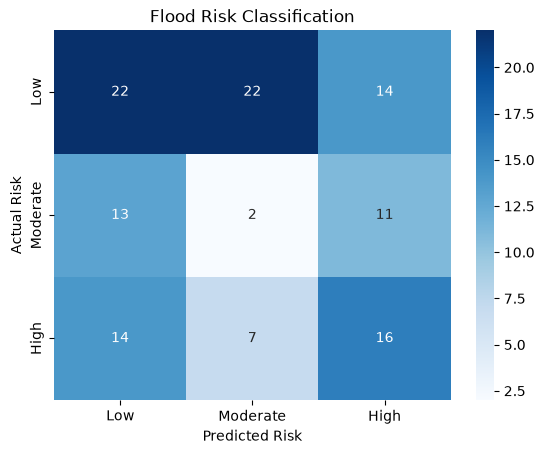

In [14]:
labels = ["Low", "Moderate", "High"]

cm = confusion_matrix(y_test, predictions, labels=labels)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=labels,
    yticklabels=labels,
    cmap="Blues"
)

plt.xlabel("Predicted Risk")
plt.ylabel("Actual Risk")
plt.title("Flood Risk Classification")
plt.show()

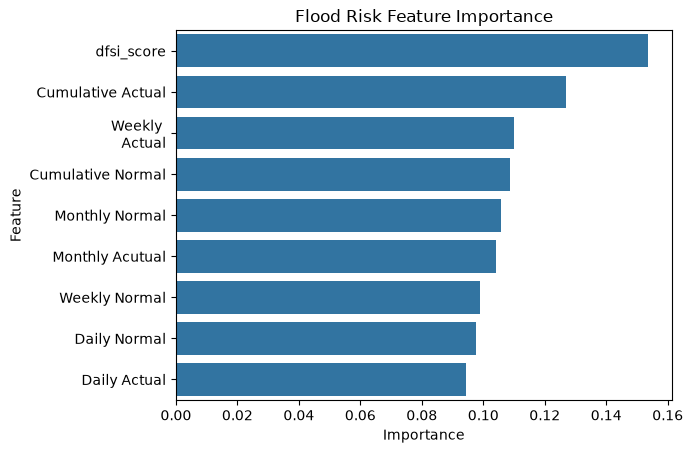

,Feature,Importance
8,dfsi_score,0.153683
4,Cumulative Actual,0.126978
2,Weekly \nActual,0.109917
5,Cumulative Normal,0.108536
7,Monthly Normal,0.105737
6,Monthly Acutual,0.104117
3,Weekly Normal,0.098975
1,Daily Normal,0.097709
0,Daily Actual,0.094348


In [15]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Flood Risk Feature Importance")
plt.show()

importance

In [16]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(model, MODEL_DIR / "floodguard_model.joblib")

joblib.dump(
    list(X.columns),
    MODEL_DIR / "model_features.joblib"
)

print("Model saved successfully!")

Model saved successfully!


In [1]:
print("end")

end
